In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("car_resale_prices.csv")

In [4]:
df.head()

,Unnamed: 0,full_name,resale_price,registered_year,engine_capacity,insurance,transmission_type,kms_driven,owner_type,fuel_type,max_power,seats,mileage,body_type,city
0,0,2017 Maruti Baleno 1.2 Alpha,₹ 5.45 Lakh,2017,1197 cc,Third Party insurance,Manual,"40,000 Kms",First Owner,Petrol,83.1bhp,5.0,21.4 kmpl,Hatchback,Agra
1,1,2018 Tata Hexa XTA,₹ 10 Lakh,2018,2179 cc,Third Party insurance,Automatic,"70,000 Kms",First Owner,Diesel,153.86bhp,7.0,17.6 kmpl,MUV,Agra
2,2,2015 Maruti Swift Dzire VXI,₹ 4.50 Lakh,2015,1197 cc,Third Party insurance,Manual,"70,000 Kms",Second Owner,Petrol,83.14bhp,5.0,20.85 kmpl,Sedan,Agra
3,3,2015 Maruti Swift Dzire VXI,₹ 4.50 Lakh,2015,1197 cc,Third Party insurance,Manual,"70,000 Kms",Second Owner,Petrol,83.14bhp,5.0,20.85 kmpl,Sedan,Agra
4,4,2009 Hyundai i10 Magna 1.1,₹ 1.60 Lakh,2009,1086 cc,Third Party insurance,Manual,"80,000 Kms",First Owner,Petrol,68.05bhp,5.0,19.81 kmpl,Hatchback,Agra


In [5]:
price_col = df.pop("resale_price")
df["resale_price"] = price_col

In [6]:
df.head()

,Unnamed: 0,full_name,registered_year,engine_capacity,insurance,transmission_type,kms_driven,owner_type,fuel_type,max_power,seats,mileage,body_type,city,resale_price
0,0,2017 Maruti Baleno 1.2 Alpha,2017,1197 cc,Third Party insurance,Manual,"40,000 Kms",First Owner,Petrol,83.1bhp,5.0,21.4 kmpl,Hatchback,Agra,₹ 5.45 Lakh
1,1,2018 Tata Hexa XTA,2018,2179 cc,Third Party insurance,Automatic,"70,000 Kms",First Owner,Diesel,153.86bhp,7.0,17.6 kmpl,MUV,Agra,₹ 10 Lakh
2,2,2015 Maruti Swift Dzire VXI,2015,1197 cc,Third Party insurance,Manual,"70,000 Kms",Second Owner,Petrol,83.14bhp,5.0,20.85 kmpl,Sedan,Agra,₹ 4.50 Lakh
3,3,2015 Maruti Swift Dzire VXI,2015,1197 cc,Third Party insurance,Manual,"70,000 Kms",Second Owner,Petrol,83.14bhp,5.0,20.85 kmpl,Sedan,Agra,₹ 4.50 Lakh
4,4,2009 Hyundai i10 Magna 1.1,2009,1086 cc,Third Party insurance,Manual,"80,000 Kms",First Owner,Petrol,68.05bhp,5.0,19.81 kmpl,Hatchback,Agra,₹ 1.60 Lakh


In [7]:
df.columns

Index(['Unnamed: 0', 'full_name', 'registered_year', 'engine_capacity',
       'insurance', 'transmission_type', 'kms_driven', 'owner_type',
       'fuel_type', 'max_power', 'seats', 'mileage', 'body_type', 'city',
       'resale_price'],
      dtype='object')

In [8]:
df.drop(columns=["Unnamed: 0"], inplace = True)

In [9]:
df.head()

,full_name,registered_year,engine_capacity,insurance,transmission_type,kms_driven,owner_type,fuel_type,max_power,seats,mileage,body_type,city,resale_price
0,2017 Maruti Baleno 1.2 Alpha,2017,1197 cc,Third Party insurance,Manual,"40,000 Kms",First Owner,Petrol,83.1bhp,5.0,21.4 kmpl,Hatchback,Agra,₹ 5.45 Lakh
1,2018 Tata Hexa XTA,2018,2179 cc,Third Party insurance,Automatic,"70,000 Kms",First Owner,Diesel,153.86bhp,7.0,17.6 kmpl,MUV,Agra,₹ 10 Lakh
2,2015 Maruti Swift Dzire VXI,2015,1197 cc,Third Party insurance,Manual,"70,000 Kms",Second Owner,Petrol,83.14bhp,5.0,20.85 kmpl,Sedan,Agra,₹ 4.50 Lakh
3,2015 Maruti Swift Dzire VXI,2015,1197 cc,Third Party insurance,Manual,"70,000 Kms",Second Owner,Petrol,83.14bhp,5.0,20.85 kmpl,Sedan,Agra,₹ 4.50 Lakh
4,2009 Hyundai i10 Magna 1.1,2009,1086 cc,Third Party insurance,Manual,"80,000 Kms",First Owner,Petrol,68.05bhp,5.0,19.81 kmpl,Hatchback,Agra,₹ 1.60 Lakh


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17446 entries, 0 to 17445
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   full_name          17446 non-null  object 
 1   registered_year    17377 non-null  object 
 2   engine_capacity    17432 non-null  object 
 3   insurance          17439 non-null  object 
 4   transmission_type  17446 non-null  object 
 5   kms_driven         17443 non-null  object 
 6   owner_type         17401 non-null  object 
 7   fuel_type          17446 non-null  object 
 8   max_power          17344 non-null  object 
 9   seats              17436 non-null  float64
 10  mileage            16938 non-null  object 
 11  body_type          17446 non-null  object 
 12  city               17446 non-null  object 
 13  resale_price       17446 non-null  object 
dtypes: float64(1), object(13)
memory usage: 1.9+ MB


In [11]:
#max_power columns is a mess, did you notice there are both bhp, rpm and kw values. There are some options:
#1. We can write a perfect regex function
#2. We can clean it with the help of llm api call
#3. We can just leave numbers and then clean from outliers but this is loosing a lot of data
#4. We can delete the column. Let's do this.
df.drop(columns = ["max_power"],inplace=True)

In [12]:
def convert_price(price):
    price = price.replace("₹","").replace(",","").strip().lower()
    if "lakh" in price:
        value = float(price.replace("lakh","").strip())*100000
    elif "crore" in price:
        value = float(price.replace("crore","").strip())*10000000
    else:
        value = float(price)
    return value


df["resale_price"] = df["resale_price"].apply(convert_price)

In [13]:
df["engine_capacity"] = df["engine_capacity"].str.replace("cc","")
df["kms_driven"] = df["kms_driven"].str.replace("Kms","").str.replace(",","")

In [14]:
df

,full_name,registered_year,engine_capacity,insurance,transmission_type,kms_driven,owner_type,fuel_type,seats,mileage,body_type,city,resale_price
0,2017 Maruti Baleno 1.2 Alpha,2017,1197,Third Party insurance,Manual,40000,First Owner,Petrol,5.0,21.4 kmpl,Hatchback,Agra,545000.0
1,2018 Tata Hexa XTA,2018,2179,Third Party insurance,Automatic,70000,First Owner,Diesel,7.0,17.6 kmpl,MUV,Agra,1000000.0
2,2015 Maruti Swift Dzire VXI,2015,1197,Third Party insurance,Manual,70000,Second Owner,Petrol,5.0,20.85 kmpl,Sedan,Agra,450000.0
3,2015 Maruti Swift Dzire VXI,2015,1197,Third Party insurance,Manual,70000,Second Owner,Petrol,5.0,20.85 kmpl,Sedan,Agra,450000.0
4,2009 Hyundai i10 Magna 1.1,2009,1086,Third Party insurance,Manual,80000,First Owner,Petrol,5.0,19.81 kmpl,Hatchback,Agra,160000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
17441,2013 Honda Amaze VX i-Vtech,Jul 2013,1198,Comprehensive,Manual,89000,Second Owner,Petrol,5.0,18 kmpl,Sedan,Delhi,325000.0
17442,2016 Toyota Camry 2.5 Hybrid,Jun 2016,2494,Comprehensive,Automatic,68000,First Owner,Petrol,5.0,19.16 kmpl,Sedan,Delhi,2075000.0
17443,2016 Toyota Corolla Altis GL MT,Jun 2016,1798,Comprehensive,Manual,81000,First Owner,Petrol,5.0,14.28 kmpl,Sedan,Delhi,835000.0
17444,2019 Hyundai Creta 1.6 CRDi AT SX Plus,Jun 2019,1582,Comprehensive,Automatic,20000,First Owner,Diesel,5.0,17.01 kmpl,SUV,Delhi,1395000.0


In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17446 entries, 0 to 17445
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   full_name          17446 non-null  object 
 1   registered_year    17377 non-null  object 
 2   engine_capacity    17432 non-null  object 
 3   insurance          17439 non-null  object 
 4   transmission_type  17446 non-null  object 
 5   kms_driven         17443 non-null  object 
 6   owner_type         17401 non-null  object 
 7   fuel_type          17446 non-null  object 
 8   seats              17436 non-null  float64
 9   mileage            16938 non-null  object 
 10  body_type          17446 non-null  object 
 11  city               17446 non-null  object 
 12  resale_price       17446 non-null  float64
dtypes: float64(2), object(11)
memory usage: 1.7+ MB


In [16]:
cols = ["engine_capacity","kms_driven"]
df[cols] = df[cols].apply(pd.to_numeric)

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17446 entries, 0 to 17445
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   full_name          17446 non-null  object 
 1   registered_year    17377 non-null  object 
 2   engine_capacity    17432 non-null  float64
 3   insurance          17439 non-null  object 
 4   transmission_type  17446 non-null  object 
 5   kms_driven         17443 non-null  float64
 6   owner_type         17401 non-null  object 
 7   fuel_type          17446 non-null  object 
 8   seats              17436 non-null  float64
 9   mileage            16938 non-null  object 
 10  body_type          17446 non-null  object 
 11  city               17446 non-null  object 
 12  resale_price       17446 non-null  float64
dtypes: float64(4), object(9)
memory usage: 1.7+ MB


In [18]:
df["mileage"].unique()

array(['21.4 kmpl', '17.6 kmpl', '20.85 kmpl', '19.81 kmpl', '17.19 kmpl',
       '27.28 kmpl', '15.37 kmpl', nan, '18 kmpl', '20.14 kmpl',
       '21.56 kmpl', '23.7 kmpl', '23.95 kmpl', '26.6 kmpl', '21.43 kmpl',
       '18.2 kmpl', '20.65 kmpl', '22.7 kmpl', '11.3 kmpl', '26.59 kmpl',
       '20.92 kmpl', '21.01 kmpl', '22.74 kmpl', '20.51 kmpl',
       '18.9 kmpl', '22.9 kmpl', '15.1 kmpl', '11.57 kmpl', '23.84 kmpl',
       '24.3 kmpl', '25.47 kmpl', '25.24 kmpl', '22.1 kmpl', '22.05 kmpl',
       '11.4 kmpl', '12.8 kmpl', '18.8 kmpl', '24 kmpl', '21.94 km/kg',
       '16.55 kmpl', '21 kmpl', '22.07 kmpl', '17.92 kmpl', '20.36 kmpl',
       '17.52 kmpl', '18.97 kmpl', '20 kmpl', '16.56 kmpl', '21.1 kmpl',
       '20.09 kmpl', '23.59 kmpl', '19.87 kmpl', '16 kmpl', '20.8 kmpl',
       '28.4 kmpl', '21.79 kmpl', '20.45 kmpl', '24.4 kmpl', '27.3 kmpl',
       '22.41 kmpl', '25.6 kmpl', '26.2 kmpl', '25.17 kmpl', '15.5 kmpl',
       '21.21 kmpl', '15.4 kmpl', '25.8 kmpl', '23.4 kmpl',

In [19]:
kmpl_count = df["mileage"].str.contains("kmpl").value_counts()
kmpl_count

mileage
True     16787
False      151
Name: count, dtype: int64

We have 16787 values with "kmpl" and 151 values with "km/kg". Now , we need to convert those 151 values of "km/kg" to kmpl.

In [20]:
#Extracting Numeric Value and Units
df["mileage_value"] = pd.to_numeric(df["mileage"].str.extract(r"(\d+\.?\d*)")[0], errors = "coerce")
df["mileage_unit"] = df["mileage"].str.extract(r"(kmpl|km/kg)")

conversion_factor = 1.40

#Converting km/kg to kmpl using 1.40
def convert_to_kmpl(row):
    if row["mileage_unit"] == "km/kg":
        return row["mileage_value"]/conversion_factor
    else:
        return row["mileage_value"]
    
df["mileage"] = df.apply(convert_to_kmpl, axis = 1)

In [21]:
filt = df["mileage_unit"]== "km/kg"
df[filt]

,full_name,registered_year,engine_capacity,insurance,transmission_type,kms_driven,owner_type,fuel_type,seats,mileage,body_type,city,resale_price,mileage_value,mileage_unit
49,2017 Maruti Eeco CNG 5 Seater AC BSIV,2017,1196.0,Third Party insurance,Manual,150000.0,First Owner,CNG,5.0,15.671429,Minivans,Agra,300000.0,21.94,km/kg
50,2017 Maruti Eeco CNG 5 Seater AC BSIV,2017,1196.0,Third Party insurance,Manual,150000.0,First Owner,CNG,5.0,15.671429,Minivans,Agra,300000.0,21.94,km/kg
51,2017 Maruti Eeco CNG 5 Seater AC BSIV,2017,1196.0,Third Party insurance,Manual,150000.0,First Owner,CNG,5.0,15.671429,Minivans,Agra,300000.0,21.94,km/kg
131,2022 Maruti Eeco CNG 5 Seater AC,2022,1196.0,Third Party insurance,Manual,20000.0,First Owner,CNG,5.0,14.914286,Minivans,Agra,625000.0,20.88,km/kg
132,2022 Maruti Eeco CNG 5 Seater AC,2022,1196.0,Third Party insurance,Manual,20000.0,First Owner,CNG,5.0,14.914286,Minivans,Agra,625000.0,20.88,km/kg
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16556,2021 Maruti Ertiga CNG VXI,Jun 2021,1462.0,Comprehensive,Manual,63500.0,Second Owner,CNG,7.0,18.628571,MUV,Delhi,1150000.0,26.08,km/kg
16604,2023 Maruti Alto K10 VXI S-CNG,2023,998.0,Third Party insurance,Manual,150000.0,First Owner,CNG,4.0,24.178571,Hatchback,Gurgaon,500000.0,33.85,km/kg
16632,2016 Maruti Eeco CNG 5 Seater AC BSIV,2016,1196.0,Third Party insurance,Manual,100000.0,Second Owner,CNG,5.0,15.671429,Maruti,Gurgaon,253000.0,21.94,km/kg
17165,2020 Maruti Celerio VXI CNG Optional,Jul 2020,998.0,Comprehensive,Manual,48746.0,First Owner,CNG,5.0,21.764286,Hatchback,Delhi,565000.0,30.47,km/kg


In [22]:
df.drop(columns = ["mileage_value", "mileage_unit"], inplace = True)

In [23]:
df

,full_name,registered_year,engine_capacity,insurance,transmission_type,kms_driven,owner_type,fuel_type,seats,mileage,body_type,city,resale_price
0,2017 Maruti Baleno 1.2 Alpha,2017,1197.0,Third Party insurance,Manual,40000.0,First Owner,Petrol,5.0,21.40,Hatchback,Agra,545000.0
1,2018 Tata Hexa XTA,2018,2179.0,Third Party insurance,Automatic,70000.0,First Owner,Diesel,7.0,17.60,MUV,Agra,1000000.0
2,2015 Maruti Swift Dzire VXI,2015,1197.0,Third Party insurance,Manual,70000.0,Second Owner,Petrol,5.0,20.85,Sedan,Agra,450000.0
3,2015 Maruti Swift Dzire VXI,2015,1197.0,Third Party insurance,Manual,70000.0,Second Owner,Petrol,5.0,20.85,Sedan,Agra,450000.0
4,2009 Hyundai i10 Magna 1.1,2009,1086.0,Third Party insurance,Manual,80000.0,First Owner,Petrol,5.0,19.81,Hatchback,Agra,160000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
17441,2013 Honda Amaze VX i-Vtech,Jul 2013,1198.0,Comprehensive,Manual,89000.0,Second Owner,Petrol,5.0,18.00,Sedan,Delhi,325000.0
17442,2016 Toyota Camry 2.5 Hybrid,Jun 2016,2494.0,Comprehensive,Automatic,68000.0,First Owner,Petrol,5.0,19.16,Sedan,Delhi,2075000.0
17443,2016 Toyota Corolla Altis GL MT,Jun 2016,1798.0,Comprehensive,Manual,81000.0,First Owner,Petrol,5.0,14.28,Sedan,Delhi,835000.0
17444,2019 Hyundai Creta 1.6 CRDi AT SX Plus,Jun 2019,1582.0,Comprehensive,Automatic,20000.0,First Owner,Diesel,5.0,17.01,SUV,Delhi,1395000.0


In [24]:
df["registered_year"].unique()

array(['2017', '2018', '2015', '2009', '2010', '2016', '2014', '2020',
       '2021', '2019', '2011', '2012', '2013', '2022', '2004', 'Jul 2021',
       'Dec 2018', 'Jun 2018', 'Mar 2016', 'Feb 2018', 'Oct 2014',
       'Mar 2014', 'Feb 2013', nan, 'Aug 2018', 'Jun 2019', 'Dec 2021',
       'Apr 2019', 'May 2018', 'Nov 2013', 'Sept 2022', 'Jan 2021',
       'Sept 2020', 'Jan 2015', 'Oct 2017', 'Sept 2019', 'Jul 2019',
       'Mar 2020', 'Jan 2018', 'Nov 2015', 'May 2015', 'Dec 2014',
       'Feb 2019', 'May 2016', 'Apr 2018', 'May 2021', '2008', 'Mar 2022',
       'Jun 2016', 'Jul 2020', 'Jun 2017', 'Jul 2016', 'Jun 2015',
       'Sept 2018', 'Nov 2018', 'Aug 2019', 'Jun 2021', '2006',
       'Jan 2017', 'Aug 2014', 'Jul 2013', 'Jul 2017', 'Dec 2013',
       'Sept 2016', 'Mar 2017', 'Feb 2020', 'Oct 2018', 'Jul 2022',
       'May 2014', 'Aug 2021', 'Aug 2020', 'Mar 2019', 'Jan 2016',
       'Feb 2016', 'Oct 2015', 'May 2019', 'Dec 2012', 'Nov 2021',
       'Mar 2018', 'Nov 2019', 'Aug 

In [25]:
df["registered_year"] = df["registered_year"].str.strip()
def smart_parse(val):
    try:
        return pd.to_datetime(val, format='%Y')  
    except:
        try:
            return pd.to_datetime(val)  
        except:
            return pd.NaT

df['parsed_date'] = df['registered_year'].apply(smart_parse)

df['registered_year'] = df['parsed_date'].dt.year

df['registered_year'] = df['registered_year'].astype('Int64')

In [26]:
df.drop(columns=["parsed_date"],inplace=True)

In [27]:
df

,full_name,registered_year,engine_capacity,insurance,transmission_type,kms_driven,owner_type,fuel_type,seats,mileage,body_type,city,resale_price
0,2017 Maruti Baleno 1.2 Alpha,2017,1197.0,Third Party insurance,Manual,40000.0,First Owner,Petrol,5.0,21.40,Hatchback,Agra,545000.0
1,2018 Tata Hexa XTA,2018,2179.0,Third Party insurance,Automatic,70000.0,First Owner,Diesel,7.0,17.60,MUV,Agra,1000000.0
2,2015 Maruti Swift Dzire VXI,2015,1197.0,Third Party insurance,Manual,70000.0,Second Owner,Petrol,5.0,20.85,Sedan,Agra,450000.0
3,2015 Maruti Swift Dzire VXI,2015,1197.0,Third Party insurance,Manual,70000.0,Second Owner,Petrol,5.0,20.85,Sedan,Agra,450000.0
4,2009 Hyundai i10 Magna 1.1,2009,1086.0,Third Party insurance,Manual,80000.0,First Owner,Petrol,5.0,19.81,Hatchback,Agra,160000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
17441,2013 Honda Amaze VX i-Vtech,2013,1198.0,Comprehensive,Manual,89000.0,Second Owner,Petrol,5.0,18.00,Sedan,Delhi,325000.0
17442,2016 Toyota Camry 2.5 Hybrid,2016,2494.0,Comprehensive,Automatic,68000.0,First Owner,Petrol,5.0,19.16,Sedan,Delhi,2075000.0
17443,2016 Toyota Corolla Altis GL MT,2016,1798.0,Comprehensive,Manual,81000.0,First Owner,Petrol,5.0,14.28,Sedan,Delhi,835000.0
17444,2019 Hyundai Creta 1.6 CRDi AT SX Plus,2019,1582.0,Comprehensive,Automatic,20000.0,First Owner,Diesel,5.0,17.01,SUV,Delhi,1395000.0


In [28]:
df["insurance"].unique()

array(['Third Party insurance', 'Comprehensive', 'Zero Dep',
       'Third Party', 'Not Available', nan, '2', '1'], dtype=object)

Here "Third Party Insurance" and "Third Party" are same , so let's replace

In [29]:
df["insurance"] = df["insurance"].str.replace("Third Party insurance","Third Party")
df["insurance"].unique()

array(['Third Party', 'Comprehensive', 'Zero Dep', 'Not Available', nan,
       '2', '1'], dtype=object)

In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17446 entries, 0 to 17445
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   full_name          17446 non-null  object 
 1   registered_year    17377 non-null  Int64  
 2   engine_capacity    17432 non-null  float64
 3   insurance          17439 non-null  object 
 4   transmission_type  17446 non-null  object 
 5   kms_driven         17443 non-null  float64
 6   owner_type         17401 non-null  object 
 7   fuel_type          17446 non-null  object 
 8   seats              17436 non-null  float64
 9   mileage            16938 non-null  float64
 10  body_type          17446 non-null  object 
 11  city               17446 non-null  object 
 12  resale_price       17446 non-null  float64
dtypes: Int64(1), float64(5), object(7)
memory usage: 1.7+ MB


# Handling Missing Values

In [31]:
df.isna().sum()

full_name              0
registered_year       69
engine_capacity       14
insurance              7
transmission_type      0
kms_driven             3
owner_type            45
fuel_type              0
seats                 10
mileage              508
body_type              0
city                   0
resale_price           0
dtype: int64

In [32]:
# Dropping null values from "mileage" column
df.dropna(subset=['mileage'], inplace=True)
df.reset_index(drop=True, inplace=True)


In [33]:
df

,full_name,registered_year,engine_capacity,insurance,transmission_type,kms_driven,owner_type,fuel_type,seats,mileage,body_type,city,resale_price
0,2017 Maruti Baleno 1.2 Alpha,2017,1197.0,Third Party,Manual,40000.0,First Owner,Petrol,5.0,21.40,Hatchback,Agra,545000.0
1,2018 Tata Hexa XTA,2018,2179.0,Third Party,Automatic,70000.0,First Owner,Diesel,7.0,17.60,MUV,Agra,1000000.0
2,2015 Maruti Swift Dzire VXI,2015,1197.0,Third Party,Manual,70000.0,Second Owner,Petrol,5.0,20.85,Sedan,Agra,450000.0
3,2015 Maruti Swift Dzire VXI,2015,1197.0,Third Party,Manual,70000.0,Second Owner,Petrol,5.0,20.85,Sedan,Agra,450000.0
4,2009 Hyundai i10 Magna 1.1,2009,1086.0,Third Party,Manual,80000.0,First Owner,Petrol,5.0,19.81,Hatchback,Agra,160000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
16933,2013 Honda Amaze VX i-Vtech,2013,1198.0,Comprehensive,Manual,89000.0,Second Owner,Petrol,5.0,18.00,Sedan,Delhi,325000.0
16934,2016 Toyota Camry 2.5 Hybrid,2016,2494.0,Comprehensive,Automatic,68000.0,First Owner,Petrol,5.0,19.16,Sedan,Delhi,2075000.0
16935,2016 Toyota Corolla Altis GL MT,2016,1798.0,Comprehensive,Manual,81000.0,First Owner,Petrol,5.0,14.28,Sedan,Delhi,835000.0
16936,2019 Hyundai Creta 1.6 CRDi AT SX Plus,2019,1582.0,Comprehensive,Automatic,20000.0,First Owner,Diesel,5.0,17.01,SUV,Delhi,1395000.0


In [34]:
df.isna().sum()

full_name             0
registered_year      58
engine_capacity       5
insurance             7
transmission_type     0
kms_driven            3
owner_type           40
fuel_type             0
seats                10
mileage               0
body_type             0
city                  0
resale_price          0
dtype: int64

Let's fill null values with some values like median and mode....

In [35]:
df["engine_capacity"] = df["engine_capacity"].fillna(df["engine_capacity"].median())
df["insurance"] = df["insurance"].fillna(df["insurance"].mode()[0])
df["kms_driven"] = df["kms_driven"].fillna(df["kms_driven"].median())
df["owner_type"] = df["owner_type"].fillna(df["owner_type"].mode()[0])
df["seats"] = df["seats"].fillna(df["seats"].median())
df["registered_year"] = df["registered_year"].fillna(df["registered_year"].median())

In [36]:
df.isna().sum()

full_name            0
registered_year      0
engine_capacity      0
insurance            0
transmission_type    0
kms_driven           0
owner_type           0
fuel_type            0
seats                0
mileage              0
body_type            0
city                 0
resale_price         0
dtype: int64

In [37]:
df.columns

Index(['full_name', 'registered_year', 'engine_capacity', 'insurance',
       'transmission_type', 'kms_driven', 'owner_type', 'fuel_type', 'seats',
       'mileage', 'body_type', 'city', 'resale_price'],
      dtype='object')

# Statistical Analysis

In [38]:
df.describe()

,registered_year,engine_capacity,kms_driven,seats,mileage,resale_price
count,16938.0,16938.000000,1.693800e+04,16938.000000,16938.000000,1.693800e+04
mean,2016.311489,1418.846204,5.930165e+04,5.204156,19.325707,8.408879e+05
std,3.591257,465.729776,6.422246e+04,0.659654,4.375615,1.002178e+06
min,2002.0,0.000000,3.000000e+02,2.000000,6.700000,2.800000e+04
25%,2014.0,1197.000000,3.300000e+04,5.000000,17.000000,3.750000e+05
50%,2017.0,1248.000000,5.545000e+04,5.000000,18.900000,5.750000e+05
75%,2019.0,1498.000000,8.000000e+04,5.000000,21.500000,8.800000e+05
max,2023.0,5998.000000,6.275000e+06,14.000000,140.000000,2.250000e+07


In [39]:
categorical_columns = ["insurance","transmission_type","owner_type","fuel_type","body_type","city"]
for col in categorical_columns:
    print(df[col].value_counts())
    print()

insurance
Third Party      9282
Comprehensive    6194
Zero Dep          819
Not Available     635
1                   5
2                   3
Name: count, dtype: int64

transmission_type
Manual       12319
Automatic     4619
Name: count, dtype: int64

owner_type
First Owner     11901
Second Owner     4095
Third Owner       765
Fourth Owner      127
Fifth Owner        50
Name: count, dtype: int64

fuel_type
Petrol      11114
Diesel       5326
CNG           465
LPG            25
Electric        8
Name: count, dtype: int64

body_type
Hatchback        7273
Sedan            4752
SUV              4028
MUV               736
Minivans           65
Maruti             19
Pickup              9
Coupe               8
Cars                8
Tata                7
Mercedes-Benz       6
Jaguar              3
Chevrolet           3
Wagon               3
Mahindra            3
Toyota              2
BMW                 2
Convertibles        2
Datsun              2
Honda               2
Audi                1
V

In [40]:
avg_resale_price = df["resale_price"].mean()
print(f'Average Resale Price is: {avg_resale_price}')

Average Resale Price is: 840887.8665722045


In [41]:
print("Engine Capacity Statistics:")
print(df["engine_capacity"].describe())

Engine Capacity Statistics:
count    16938.000000
mean      1418.846204
std        465.729776
min          0.000000
25%       1197.000000
50%       1248.000000
75%       1498.000000
max       5998.000000
Name: engine_capacity, dtype: float64


- #### Median Mileage Per Year

In [42]:
median_mileage_by_year = df.groupby("registered_year")["mileage"].median()
median_mileage_by_year.sort_values(ascending=False)
median_mileage_by_year

registered_year
2002    16.100000
2003    13.750000
2004    16.000000
2005    14.900000
2006    15.700000
2007    16.800000
2008    17.800000
2009    17.000000
2010    18.000000
2011    18.300000
2012    19.000000
2013    19.000000
2014    19.100000
2015    18.900000
2016    19.100000
2017    19.120000
2018    19.870000
2019    19.500000
2020    19.330000
2021    18.760000
2022    18.921429
2023    19.005000
Name: mileage, dtype: float64

- #### Average Car Price By Year

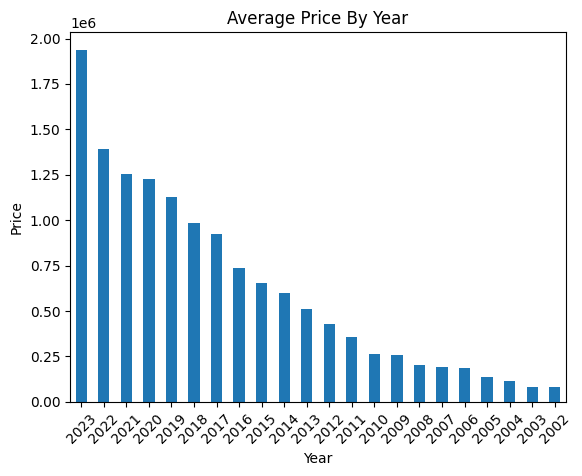

In [43]:
avg_price_by_year = df.groupby("registered_year")["resale_price"].mean().sort_values(ascending=False)
avg_price_by_year.plot(kind="bar")
plt.title("Average Price By Year")
plt.xlabel("Year")
plt.ylabel("Price")
plt.xticks(rotation = 45)
plt.show()

In [44]:
ls

 Volume in drive C is Windows-SSD
 Volume Serial Number is 2482-D5B5

 Directory of c:\Users\sreeshanth\OneDrive\Documents\LINEAR REGRESSION

09-07-2025  16:43    <DIR>          .
14-07-2026  20:32    <DIR>          ..
08-07-2025  12:33         2,824,805 car_resale_prices.csv
10-07-2025  19:43             1,612 loop.txt
14-07-2026  21:09           570,683 notebook.ipynb
               3 File(s)      3,397,100 bytes
               2 Dir(s)  147,459,973,120 bytes free


- #### Cities With Most And Least Car Listings

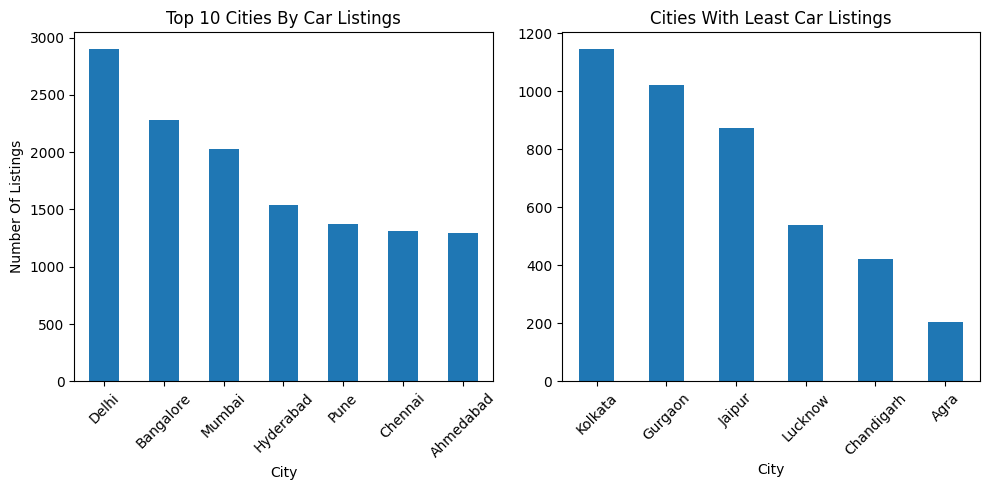

In [45]:
top_cities = df["city"].value_counts().head(7)
least_cities = df["city"].value_counts().tail(6)
fig, ax = plt.subplots(1,2,figsize = (10,5))
top_cities.plot(kind= "bar",ax = ax[0],title = "Top 10 Cities By Car Listings")
ax[0].set_xlabel("City")
ax[0].set_ylabel("Number Of Listings")
ax[0].tick_params(axis='x', rotation=45)

least_cities.plot(kind= "bar",ax=ax[1],title = "Cities With Least Car Listings")
ax[1].set_xlabel("City")
ax[1].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()



- #### Average Price By Fuel Type

Average resale price by fuel type:
 fuel_type
Diesel      1.238839e+06
Petrol      6.673847e+05
CNG         4.715398e+05
Electric    4.137500e+05
LPG         2.005400e+05
Name: resale_price, dtype: float64


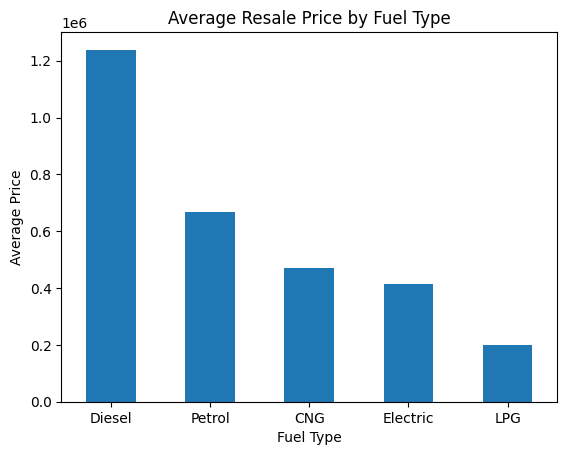

In [46]:
fuel_type_price = df.groupby("fuel_type")["resale_price"].mean().sort_values(ascending = False)
print("Average resale price by fuel type:\n", fuel_type_price)

fuel_type_price.plot(kind = "bar",title="Average Resale Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Average Price")
plt.xticks(rotation=0)
plt.show()


- #### Distribution Of Resale Price

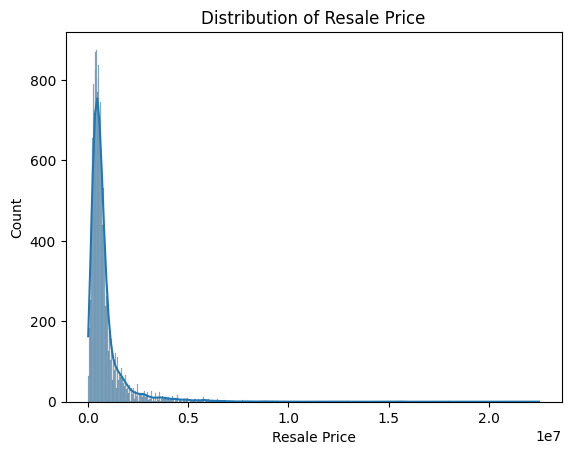

In [47]:
sns.histplot(df['resale_price'], kde=True)
plt.title("Distribution of Resale Price")
plt.xlabel("Resale Price")
plt.ylabel("Count")
plt.show()

- #### Maximum Engine Size By Fuel Type

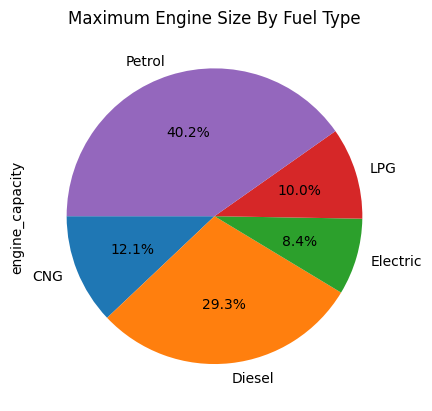

In [48]:
engine_size_by_fuel = df.groupby("fuel_type")["engine_capacity"].max()
engine_size_by_fuel.plot(kind="pie",title="Maximum Engine Size By Fuel Type",autopct = "%1.1f%%",startangle= 180)
plt.show()

- #### Resale Price By Transmission Type

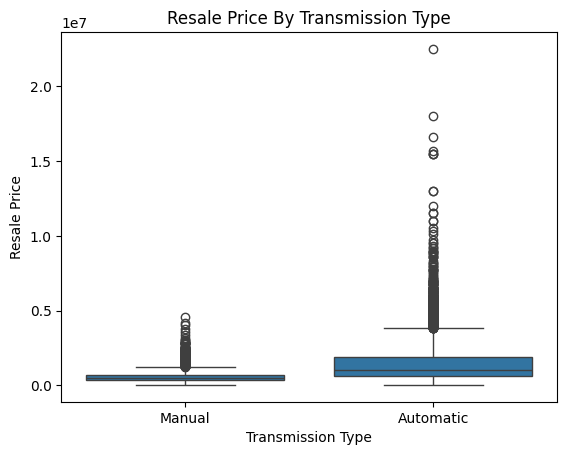

In [49]:
sns.boxplot(data=df,x="transmission_type",y="resale_price")
plt.title("Resale Price By Transmission Type")
plt.xlabel("Transmission Type")
plt.ylabel("Resale Price")
plt.show()

- #### Engine Capacity By Price - Scatter Plot

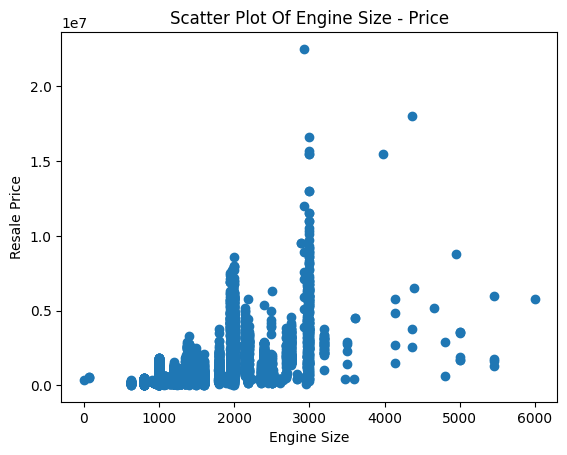

In [50]:
plt.scatter(df["engine_capacity"],df["resale_price"])
plt.title("Scatter Plot Of Engine Size - Price")
plt.xlabel("Engine Size")
plt.ylabel("Resale Price")
plt.show()

In [51]:
numeric_df = df.select_dtypes(include=["float64"])
correlation_matrix = numeric_df.corr()

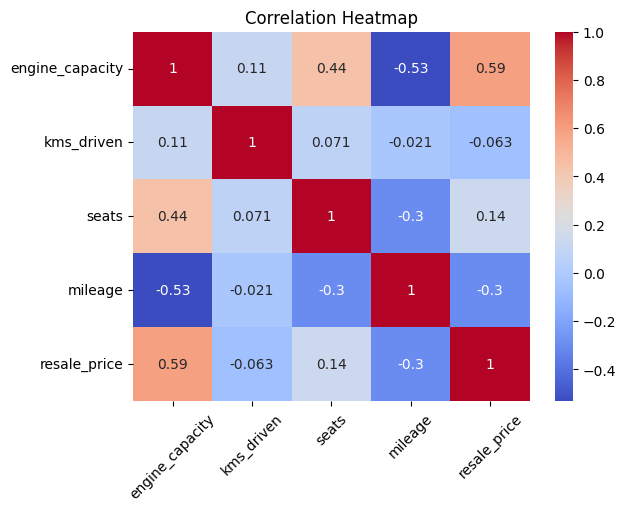

In [52]:
sns.heatmap(correlation_matrix, annot=True,cmap = "coolwarm")
plt.title("Correlation Heatmap")
plt.xticks(rotation = 45)
plt.show()

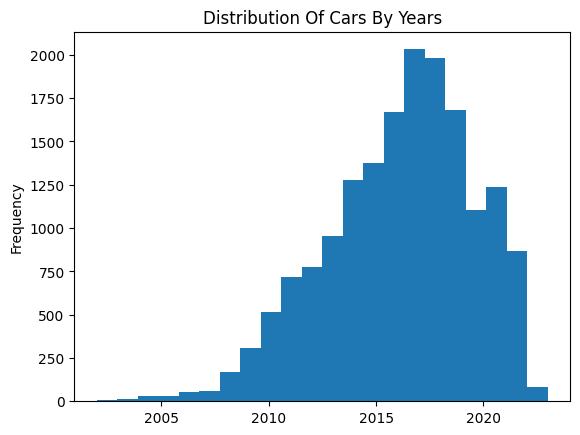

In [53]:
df["registered_year"].plot.hist(bins = 22)
plt.title("Distribution Of Cars By Years")
plt.show()

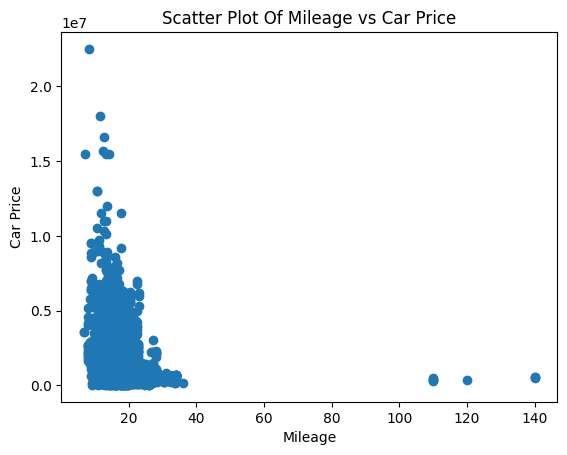

In [54]:
plt.scatter(x=df["mileage"], y = df["resale_price"])
plt.title("Scatter Plot Of Mileage vs Car Price")
plt.xlabel("Mileage")
plt.ylabel("Car Price")
plt.show()

In [55]:
# sns.pairplot(df[['engine_capacity', 'mileage', 'kms_driven', 'resale_price']])
# # plt.show()

## Implementing Linear Regression

- #### One-Hot Encoding

In [56]:
X = df.iloc[:,:-1]
X

,full_name,registered_year,engine_capacity,insurance,transmission_type,kms_driven,owner_type,fuel_type,seats,mileage,body_type,city
0,2017 Maruti Baleno 1.2 Alpha,2017,1197.0,Third Party,Manual,40000.0,First Owner,Petrol,5.0,21.40,Hatchback,Agra
1,2018 Tata Hexa XTA,2018,2179.0,Third Party,Automatic,70000.0,First Owner,Diesel,7.0,17.60,MUV,Agra
2,2015 Maruti Swift Dzire VXI,2015,1197.0,Third Party,Manual,70000.0,Second Owner,Petrol,5.0,20.85,Sedan,Agra
3,2015 Maruti Swift Dzire VXI,2015,1197.0,Third Party,Manual,70000.0,Second Owner,Petrol,5.0,20.85,Sedan,Agra
4,2009 Hyundai i10 Magna 1.1,2009,1086.0,Third Party,Manual,80000.0,First Owner,Petrol,5.0,19.81,Hatchback,Agra
...,...,...,...,...,...,...,...,...,...,...,...,...
16933,2013 Honda Amaze VX i-Vtech,2013,1198.0,Comprehensive,Manual,89000.0,Second Owner,Petrol,5.0,18.00,Sedan,Delhi
16934,2016 Toyota Camry 2.5 Hybrid,2016,2494.0,Comprehensive,Automatic,68000.0,First Owner,Petrol,5.0,19.16,Sedan,Delhi
16935,2016 Toyota Corolla Altis GL MT,2016,1798.0,Comprehensive,Manual,81000.0,First Owner,Petrol,5.0,14.28,Sedan,Delhi
16936,2019 Hyundai Creta 1.6 CRDi AT SX Plus,2019,1582.0,Comprehensive,Automatic,20000.0,First Owner,Diesel,5.0,17.01,SUV,Delhi


In [57]:
X['car_age'] = 2025 - X["registered_year"]

In [58]:
X.head()

,full_name,registered_year,engine_capacity,insurance,transmission_type,kms_driven,owner_type,fuel_type,seats,mileage,body_type,city,car_age
0,2017 Maruti Baleno 1.2 Alpha,2017,1197.0,Third Party,Manual,40000.0,First Owner,Petrol,5.0,21.40,Hatchback,Agra,8
1,2018 Tata Hexa XTA,2018,2179.0,Third Party,Automatic,70000.0,First Owner,Diesel,7.0,17.60,MUV,Agra,7
2,2015 Maruti Swift Dzire VXI,2015,1197.0,Third Party,Manual,70000.0,Second Owner,Petrol,5.0,20.85,Sedan,Agra,10
3,2015 Maruti Swift Dzire VXI,2015,1197.0,Third Party,Manual,70000.0,Second Owner,Petrol,5.0,20.85,Sedan,Agra,10
4,2009 Hyundai i10 Magna 1.1,2009,1086.0,Third Party,Manual,80000.0,First Owner,Petrol,5.0,19.81,Hatchback,Agra,16


In [59]:
categorical_cols = ["transmission_type","fuel_type"]
X = pd.get_dummies(X, columns = categorical_cols)
X.drop(columns=["full_name","registered_year","insurance","owner_type","body_type","city"],inplace=True)
X

,engine_capacity,kms_driven,seats,mileage,car_age,transmission_type_Automatic,transmission_type_Manual,fuel_type_CNG,fuel_type_Diesel,fuel_type_Electric,fuel_type_LPG,fuel_type_Petrol
0,1197.0,40000.0,5.0,21.40,8,False,True,False,False,False,False,True
1,2179.0,70000.0,7.0,17.60,7,True,False,False,True,False,False,False
2,1197.0,70000.0,5.0,20.85,10,False,True,False,False,False,False,True
3,1197.0,70000.0,5.0,20.85,10,False,True,False,False,False,False,True
4,1086.0,80000.0,5.0,19.81,16,False,True,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...
16933,1198.0,89000.0,5.0,18.00,12,False,True,False,False,False,False,True
16934,2494.0,68000.0,5.0,19.16,9,True,False,False,False,False,False,True
16935,1798.0,81000.0,5.0,14.28,9,False,True,False,False,False,False,True
16936,1582.0,20000.0,5.0,17.01,6,True,False,False,True,False,False,False


In [60]:
y = df.iloc[:,-1]

Q1 = y.quantile(0.25)
Q3 = y.quantile(0.75)
IQR = Q3 - Q1

# Define bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filter out the outliers
mask = (y>= lower_bound) & (y<= upper_bound)
X = X[mask]
y = y[mask]

y = y/100000
y

0         5.45
1        10.00
2         4.50
3         4.50
4         1.60
         ...  
16932     8.60
16933     3.25
16935     8.35
16936    13.95
16937     6.50
Name: resale_price, Length: 15260, dtype: float64

In [61]:
X

,engine_capacity,kms_driven,seats,mileage,car_age,transmission_type_Automatic,transmission_type_Manual,fuel_type_CNG,fuel_type_Diesel,fuel_type_Electric,fuel_type_LPG,fuel_type_Petrol
0,1197.0,40000.0,5.0,21.40,8,False,True,False,False,False,False,True
1,2179.0,70000.0,7.0,17.60,7,True,False,False,True,False,False,False
2,1197.0,70000.0,5.0,20.85,10,False,True,False,False,False,False,True
3,1197.0,70000.0,5.0,20.85,10,False,True,False,False,False,False,True
4,1086.0,80000.0,5.0,19.81,16,False,True,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...
16932,1999.0,67634.0,5.0,14.62,9,True,False,False,False,False,False,True
16933,1198.0,89000.0,5.0,18.00,12,False,True,False,False,False,False,True
16935,1798.0,81000.0,5.0,14.28,9,False,True,False,False,False,False,True
16936,1582.0,20000.0,5.0,17.01,6,True,False,False,True,False,False,False


In [75]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [69]:
x_train , x_test , y_train , y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [70]:
scaler = StandardScaler()
x_train_scaled= scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [71]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.01),
    "Decision Tree": DecisionTreeRegressor(max_depth=8, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state = 42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'XGBoost': XGBRegressor(random_state=42),
    'SVR': SVR(kernel='rbf')
}

In [ ]:
results = []

for name, model in models.items():
    model.fit(x_train_scaled, y_train)

    y_pred = model.predict(x_test_scaled)

    mse = mean_squared_error(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    cv_scores = cross_val_score(model, x_train_scaled, y_train, cv=5, scoring = "r2")

    results.append([name, mse, mae, rmse, r2, np.mean(cv_scores)])

results_df = pd.DataFrame(results, columns = ["Model", "MSE", "MAE", "RMSE", "R2", "CV_R2"])

results_df.sort_values('R2', ascending=False, inplace=True)
print(results_df)

               Model       MSE       MAE      RMSE        R2  \
6            XGBoost  1.301352  0.782616  1.140768  0.869695   
4      Random Forest  1.373063  0.795144  1.171778  0.862515   
5  Gradient Boosting  1.886145  0.982591  1.373370  0.811140   
3      Decision Tree  1.963517  0.956846  1.401255  0.803393   
7                SVR  2.282787  1.035435  1.510889  0.771424   
2              Lasso  3.193749  1.304393  1.787106  0.680209   
1              Ridge  3.198195  1.307474  1.788350  0.679764   
0  Linear Regression  3.198236  1.307499  1.788361  0.679760   

                                               CV_R2  
6  [0.867998189441863, 0.871823171267659, 0.86890...  
4  [0.8643214827958431, 0.8614119564505941, 0.862...  
5  [0.8311367816501847, 0.8232659572885905, 0.811...  
3  [0.8262553909301928, 0.8132939881797191, 0.810...  
7  [0.7962125001225818, 0.7826175824259246, 0.772...  
2  [0.7021517074453889, 0.6980449391952581, 0.691...  
1  [0.7019624145363644, 0.698146033851

In [73]:
results_df

,Model,MSE,MAE,RMSE,R2,CV_R2
6,XGBoost,1.301352,0.782616,1.140768,0.869695,"[0.867998189441863, 0.871823171267659, 0.86890..."
4,Random Forest,1.373063,0.795144,1.171778,0.862515,"[0.8643214827958431, 0.8614119564505941, 0.862..."
5,Gradient Boosting,1.886145,0.982591,1.373370,0.811140,"[0.8311367816501847, 0.8232659572885905, 0.811..."
3,Decision Tree,1.963517,0.956846,1.401255,0.803393,"[0.8262553909301928, 0.8132939881797191, 0.810..."
7,SVR,2.282787,1.035435,1.510889,0.771424,"[0.7962125001225818, 0.7826175824259246, 0.772..."
2,Lasso,3.193749,1.304393,1.787106,0.680209,"[0.7021517074453889, 0.6980449391952581, 0.691..."
1,Ridge,3.198195,1.307474,1.788350,0.679764,"[0.7019624145363644, 0.6981460338518225, 0.692..."
0,Linear Regression,3.198236,1.307499,1.788361,0.679760,"[0.701959186614695, 0.6981511303809033, 0.6920..."


- The Top Two Models Are XGBoost and Random Forest. Therefore, Tune the XGBoost and Random Forest Models

### Tuning XGBoost Model


In [77]:
param_grid_xgb = {
    "n_estimators": [100, 200, 300, 500],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "max_depth": [3, 5, 7, 9],
    "min_child_weight": [1, 3, 5],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "gamma": [0, 0.1, 0.2, 0.3],
    "reg_alpha": [0, 0.1, 1],
    "reg_lambda": [1, 2, 5]
}

In [78]:
xgb = XGBRegressor(random_state = 42, objective="reg:squarederror")

xgb_search = RandomizedSearchCV(
                xgb,
                param_distributions=param_grid_xgb,
                n_iter = 30,
                cv=5,
                random_state=42,
                n_jobs=-1

)

xgb_search.fit(x_train_scaled, y_train)

print("Best Paramaeters: ", xgb_search.best_params_)
print("Best Score: ", xgb_search.best_score_)

Best Paramaeters:  {'subsample': 0.6, 'reg_lambda': 2, 'reg_alpha': 0, 'n_estimators': 300, 'min_child_weight': 3, 'max_depth': 9, 'learning_rate': 0.03, 'gamma': 0, 'colsample_bytree': 0.6}
Best Score:  0.8753242511731727


In [ ]:
xgb_best_model = xgb_search.best_estimator_

y_pred_xgb = xgb_best_model.predict(x_test_scaled)

mse = mean_squared_error(y_test, y_pred_xgb)
mae = mean_absolute_error(y_test, y_pred_xgb)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_xgb)
cv_scores = cross_val_score(xgb_best_model, x_train_scaled, y_train, cv=5, scoring = "r2")

print(f"The Mean Squared Error for XGBoost Regressor is {mse}")
print(f"The Mean Absolute Error for XGBoost Regressor is {mae}")
print(f"The Root Mean Squared Error for XGBoost Regressor is {rmse}")
print(f"The R2 for XGBoost Regressor is {r2:.4f}")
print(f"The Mean of cv_scores for XGBoost Regressor is {np.mean(cv_scores)}")

The Mean Squared Error for XGBoost Regressor is 1.335965038506169
The Mean Absolute Error for XGBoost Regressor is 0.7958580514736984
The Root Mean Squared Error for XGBoost Regressor is 1.1558395383902424
The R2 for XGBoost Regressor is 0.8662
The Mean of cv_scores for XGBoost Regressor is 0.8760142042009853


In [80]:
param_grid_rf = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [None, 10, 20, 30, 40],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"],
    "bootstrap": [True, False]
}

In [81]:
rf_search = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_distributions=param_grid_rf,
    n_iter=30,
    scoring="r2",
    cv=5,
    random_state=42,
    n_jobs=-1
)

rf_search.fit(x_train_scaled, y_train)

print(rf_search.best_params_)
print(rf_search.best_score_)

{'n_estimators': 500, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 30, 'bootstrap': True}
0.8675518909603097


In [ ]:
rf_best_model = rf_search.best_estimator_

y_pred_rf = rf_best_model.predict(x_test_scaled)

mse = mean_squared_error(y_test, y_pred_rf)
mae = mean_absolute_error(y_test, y_pred_rf)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_rf)
cv_scores = cross_val_score(rf_best_model, x_train_scaled, y_train, cv=5, scoring = "r2")

print(f"The Mean Squared Error for Random Forest Regressor is {mse}")
print(f"The Mean Absolute Error for Random Forest Regressor is {mae}")
print(f"The Root Mean Squared Error for Random Forest Regressor is {rmse}")
print(f"The R2 for Random Forest Regressor is {r2:.4f}")
print(f"The Mean of cv_scores for Random Forest Regressor is {np.mean(cv_scores)}")

The Mean Squared Error for Random Forest Regressor is 1.335965038506169
The Mean Absolute Error for Random Forest Regressor is 0.7958580514736984
The Root Mean Squared Error for Random Forest Regressor is 1.1558395383902424
The R2 for Random Forest Regressor is 0.8662
The Mean of cv_scores for Random Forest Regressor is 0.8675518909603097


Text(0, 0.5, 'Predicted Price')

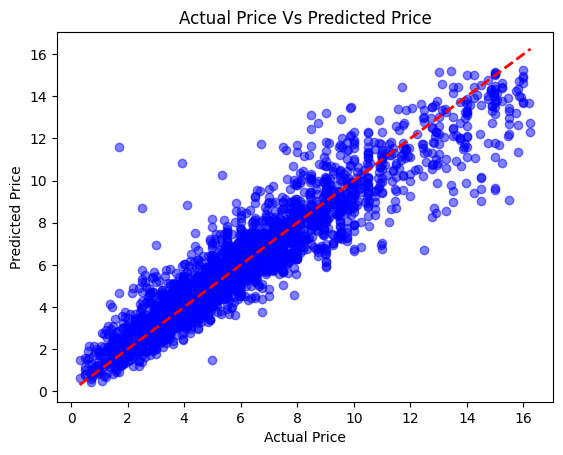

In [88]:
plt.scatter(y_test, y_pred_xgb, alpha=0.5, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(),y_test.max()], 'r--', linewidth=2)  
plt.title("Actual Price Vs Predicted Price")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")

The Actual vs Predicted plot shows that most predictions lie close to the ideal 45° reference line, indicating that the XGBoost model predicts resale prices with good accuracy. A slightly larger spread is observed for high-priced cars, suggesting greater prediction uncertainty for expensive vehicles.

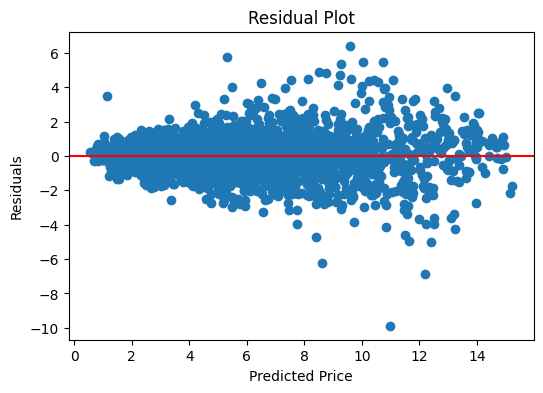

In [100]:
residuals = y_test - y_pred_xgb

plt.figure(figsize=(6,4))
plt.scatter(y_pred, residuals)
plt.axhline(y=0, color='red')
plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

In [89]:
import pandas as pd
import matplotlib.pyplot as plt

importance = xgb_best_model.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
}).sort_values("Importance", ascending=False)

print(feature_importance)

                        Feature  Importance
4                       car_age    0.186056
5   transmission_type_Automatic    0.162388
0               engine_capacity    0.160598
8              fuel_type_Diesel    0.138069
6      transmission_type_Manual    0.130425
3                       mileage    0.058786
11             fuel_type_Petrol    0.053314
2                         seats    0.047347
1                    kms_driven    0.033298
7                 fuel_type_CNG    0.022384
9            fuel_type_Electric    0.005703
10                fuel_type_LPG    0.001633


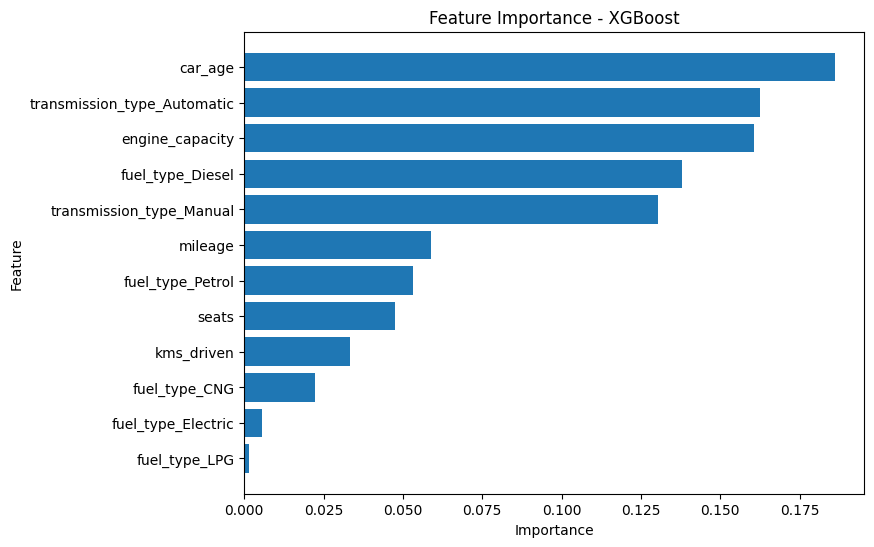

In [91]:
feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(8,6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importance - XGBoost")

plt.show()

In [92]:
import joblib

joblib.dump(xgb_best_model, "car_resale_price_prediction_model.pkl")
joblib.dump(scaler,"scaler.pkl")
print("Model And Scaler Saved!!")



Model And Scaler Saved!!


In [93]:
model = joblib.load("car_resale_price_prediction_model.pkl")
scaler = joblib.load("scaler.pkl")

In [99]:
sample = pd.DataFrame({
    "engine_capacity": [1998],
    "kms_driven": [30000],
    "seats": [5],
    "mileage": [20.0],
    "car_age": [2],
    "transmission_type_Automatic": [1],
    "transmission_type_Manual": [0],
    "fuel_type_CNG": [0],
    "fuel_type_Diesel": [1],
    "fuel_type_Electric": [0],
    "fuel_type_LPG": [0],
    "fuel_type_Petrol": [0]
})

sample_scaled = scaler.transform(sample)

prediction = model.predict(sample_scaled)

print(f"The Car Resale Price is: ₹{prediction[0]:,.2f} Lakhs")

The Car Resale Price is: ₹14.10 Lakhs


In [115]:
param_grid_rf = {
    'n_estimators': [100, 200, 300],          # Number of trees
    'criterion': ['squared_error', 'absolute_error'],  
    'max_depth': [None, 5, 10, 20, 30],      
    'min_samples_split': [2, 5, 10],         
    'min_samples_leaf': [1, 2, 4],           
    'max_features': ['sqrt', 'log2', None],  
    'bootstrap': [True, False]               # Whether bootstrap samples are used
}